# Introduction, data sources and exploratory analysis

## Setup

In [1]:
import os, sys, json, glob
from pathlib import Path
from collections import Counter

IN_COLAB = "google.colab" in sys.modules
if not Path("ner").exists() and Path("../ner").exists():
    os.chdir("..")   # parts/ notebooks run from the repository root
if IN_COLAB and not Path("ner").exists():
    !git clone -b final-submission https://github.com/lofty14/bert-ner-baseline.git
    %cd bert-ner-baseline
    !pip -q install transformers==5.22.0 accelerate==1.15.0 seqeval==1.2.2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(".").resolve()
sys.path.insert(0, str(ROOT))
pd.set_option("display.precision", 2)
print("repo root:", ROOT)

repo root: /Users/chonglichen/UNSW/COMP9444/group_project


## 1. Introduction and problem statement
*Owner: Yuchen Li. Rubric: clearly define the problem statement or purpose of the project.*

Points to cover (replace this list with prose):
- Biomedical NER: find disease mentions in PubMed abstracts and tag them at the token level (BIO scheme).
- Why it matters: literature search, knowledge-base curation, downstream relation extraction.
- Why it is hard: abbreviations, multi-word and nested-looking spans, many diseases unseen in training.
- Project objectives (from the course brief): (1) fine-tune BioBERT and PubMedBERT, (2) improve generalisation with a
  domain-adaptation technique, (3) evaluate with precision, recall and F1.
- Our questions: how much do biomedical pre-trained encoders gain over general BERT under one fair protocol, and can a
  small amount of domain-adaptive pre-training (DAPT) recover part of that gain cheaply?

## 2. Data sources
*Owner: Yuchen Li. Rubric: data sources are clearly documented and described.*

- **NCBI Disease corpus** (Doğan et al., 2014): 793 PubMed abstracts, disease mentions annotated by 12 annotators
  in pairs. Official split: 593 / 100 / 100 abstracts (train / dev / test).
- We use the sentence-level CoNLL release (`spyysalo/ncbi-disease`, the version used by BioBERT). The loader
  downloads the files once and checks each file against a pinned SHA-256 hash.
- Labels: `O`, `B-Disease`, `I-Disease`.
- DAPT corpus (section 4.5): about 29,000 PubMed abstracts collected by the team; checked for overlap with the
  NCBI test abstracts.

In [2]:
from ner.data import load_ncbi, LABELS
splits, audit = load_ncbi(audit=False)
print("labels:", LABELS)
for name, rows in splits.items():
    print(f"{name:>10}: {len(rows):5d} sentences")

labels: ['O', 'B-Disease', 'I-Disease']
     train:  5432 sentences
validation:   923 sentences
      test:   940 sentences


## 3. Exploratory data analysis
*Owners: Yuchen Li, Alex Shen. Rubric (3 marks): properties, number of classes, pre-processing, and challenging aspects
of the data.*

In [3]:
def entities(tags):
    """Strict IOB2 spans as (start, end) token offsets, end exclusive."""
    spans, start = [], None
    for i, t in enumerate(tags + ["O"]):
        if t == "B-Disease" or t == "O" or (t == "I-Disease" and start is None):
            if start is not None:
                spans.append((start, i))
                start = None
            if t == "B-Disease":
                start = i
    return spans

rows = []
for name, data in splits.items():
    n_tok = sum(len(t) for t, _ in data)
    tag_counts = Counter(tag for _, tags in data for tag in tags)
    ents = [(toks, s) for toks, tags in data for s in entities(tags)]
    rows.append({
        "split": name,
        "sentences": len(data),
        "tokens": n_tok,
        "mentions": len(ents),
        "sentences with >=1 mention (%)": 100 * sum(bool(entities(tags)) for _, tags in data) / len(data),
        "O tokens (%)": 100 * tag_counts["O"] / n_tok,
        "B tokens (%)": 100 * tag_counts["B-Disease"] / n_tok,
        "I tokens (%)": 100 * tag_counts["I-Disease"] / n_tok,
        "mean mention length (tokens)": np.mean([e - s for _, (s, e) in ents]),
    })
eda = pd.DataFrame(rows).set_index("split")
eda

,sentences,tokens,mentions,sentences with >=1 mention (%),O tokens (%),B tokens (%),I tokens (%),mean mention length (tokens)
split,,,,,,,,
train,5432,136086,5145,53.94,91.72,3.78,4.50,2.19
validation,923,23969,787,52.98,92.17,3.28,4.55,2.39
test,940,24497,960,57.34,91.64,3.92,4.44,2.13


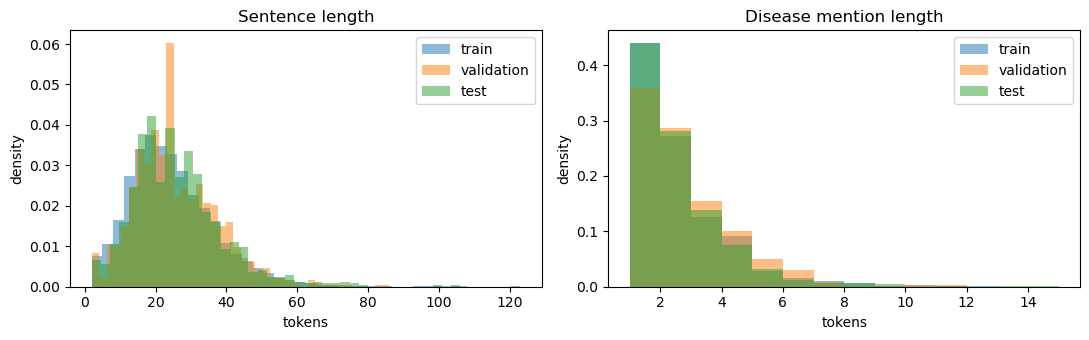

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, data in splits.items():
    axes[0].hist([len(t) for t, _ in data], bins=40, alpha=0.5, density=True, label=name)
    lens = [e - s for _, tags in data for s, e in entities(tags)]
    axes[1].hist(lens, bins=range(1, 16), alpha=0.5, density=True, label=name)
axes[0].set(title="Sentence length", xlabel="tokens", ylabel="density")
axes[1].set(title="Disease mention length", xlabel="tokens", ylabel="density")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

In [5]:
def mention_texts(data):
    return [" ".join(toks[s:e]) for toks, tags in data for s, e in entities(tags)]

train_mentions = set(m.lower() for m in mention_texts(splits["train"]))
for name in ["validation", "test"]:
    ms = mention_texts(splits[name])
    unseen = [m for m in ms if m.lower() not in train_mentions]
    print(f"{name}: {len(ms)} mentions, {100 * len(unseen) / len(ms):.1f}% never appear as a mention in train")

print()
print("Most frequent training mentions:")
print(Counter(mention_texts(splits["train"])).most_common(15))

abbrev = [m for m in mention_texts(splits["train"]) if m.isupper() and len(m) <= 6]
print()
print(f"Upper-case abbreviations among training mentions: {len(abbrev)} "
      f"({100 * len(abbrev) / len(mention_texts(splits['train'])):.1f}%), e.g. {Counter(abbrev).most_common(8)}")

validation: 787 mentions, 35.2% never appear as a mention in train
test: 960 mentions, 37.7% never appear as a mention in train

Most frequent training mentions:
[('DM', 120), ('DMD', 109), ('APC', 91), ('ALD', 86), ('PWS', 75), ('WAS', 63), ('myotonic dystrophy', 57), ('G6PD deficiency', 57), ('HD', 55), ('PKU', 52), ('aniridia', 50), ('Duchenne muscular dystrophy', 44), ('breast cancer', 42), ('VHL', 40), ('FAP', 39)]

Upper-case abbreviations among training mentions: 1520 (29.5%), e.g. [('DM', 120), ('DMD', 109), ('APC', 91), ('ALD', 86), ('PWS', 75), ('WAS', 63), ('HD', 55), ('PKU', 52)]


In [6]:
# Leakage check between splits (exact duplicate sentences).
sent = {name: set(" ".join(t) for t, _ in data) for name, data in splits.items()}
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    print(f"{a} / {b}: {len(sent[a] & sent[b])} identical sentences")

train / validation: 5 identical sentences
train / test: 1 identical sentences
validation / test: 1 identical sentences


**Observations (to write up):**
- Three classes, heavily imbalanced: almost all tokens are `O`.
- Mentions are short but multi-word mentions are common; boundary errors are the main risk (see section 6).
- A large share of test mentions never occurs in train, so the model must generalise beyond memorising names.
- Abbreviations (e.g. `DM`, `APC`) are ambiguous between gene and disease.
- Pre-processing: sentence-level CoNLL; words are split into sub-words by each model's tokenizer and only the
  first sub-word of each word is labelled (section 4.1).